In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
dataset=pd.read_csv("/content/Lab 21 House_Rent_Dataset.csv")
dataset.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [3]:
dataset.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.746000e+03,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866
std,0.832256,7.810641e+04,634.202328,0.884532
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [4]:
dataset.isnull().sum()

,0
Posted On,0
BHK,0
Rent,0
Size,0
Floor,0
Area Type,0
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0


In [5]:
dataset.duplicated().sum()

np.int64(0)

In [6]:
num_cols=dataset.select_dtypes(include="number").columns
num_cols

Index(['BHK', 'Rent', 'Size', 'Bathroom'], dtype='object')

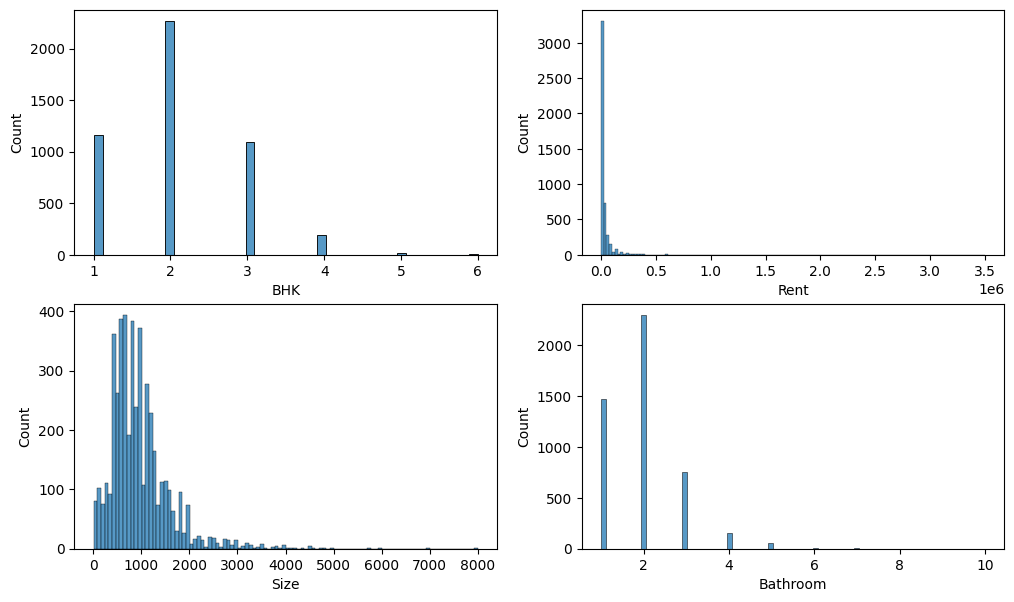

In [7]:
fig,axes=plt.subplots(2,2,figsize=(12,7))
axes=axes.flatten()
for ax,col in zip(axes,num_cols):
  sns.histplot(data=dataset,x=col,ax=ax)
plt.show()


In [11]:
cat_cols=dataset.select_dtypes(include="object").columns
cat_cols

Index(['Floor', 'Area Type', 'Area Locality', 'City', 'Furnishing Status',
       'Tenant Preferred'],
      dtype='object')

In [31]:
dataset.drop(columns=["Posted On","Point of Contact"],inplace=True)

In [32]:
dataset.head()

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom
0,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2
1,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1
2,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1
3,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1
4,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1


In [33]:
dataset["Area Locality"].value_counts()

,count
Area Locality,
Bandra West,37
Gachibowli,29
Electronic City,24
"Miyapur, NH 9",22
Velachery,22
...,...
Hoysala Nagar,1
Nagarabhavi,1
"Shamanna Garden, Wilson Garden",1


In [34]:
cat_cols=cat_cols.drop(["Floor","Area Locality"])

KeyError: "['Floor', 'Area Locality'] not found in axis"

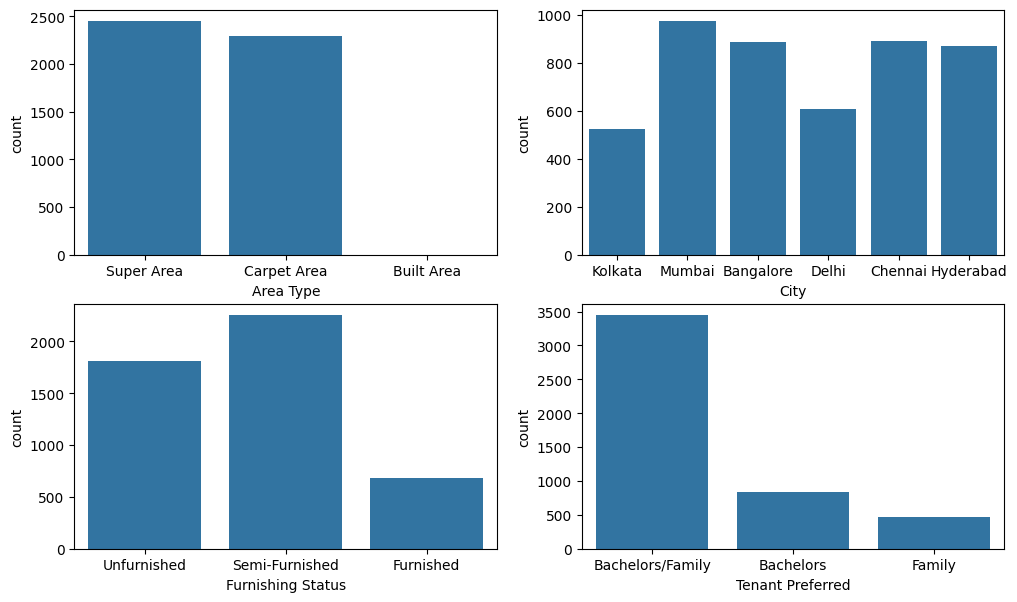

In [18]:
fig,axes=plt.subplots(2,2,figsize=(12,7))
axes=axes.flatten()
for ax,col in zip(axes,cat_cols):
  sns.countplot(data=dataset,x=col,ax=ax)
plt.show()

<Axes: xlabel='Rent'>

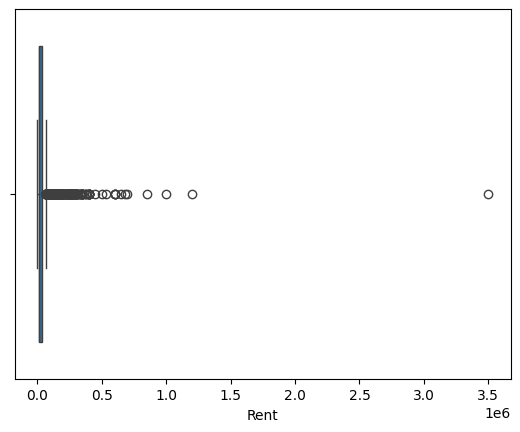

In [19]:
sns.boxplot(data=dataset,x="Rent")

In [20]:
dataset.head()

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom
0,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2
1,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1
2,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1
3,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1
4,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1


In [21]:
!pip install category_encoders

In [46]:
x=dataset.drop(columns=["Rent"])
y=np.log1p(dataset["Rent"])

In [47]:
import category_encoders as ce
encoder=ce.LeaveOneOutEncoder(return_df=True)
x=encoder.fit_transform(x,y)


In [48]:
x.head()

,BHK,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom
0,2,1100,9.308423,9.530845,8.779711,9.150821,9.575347,9.781185,2
1,2,800,9.521719,9.530561,8.160804,9.149496,9.979352,9.780984,1
2,2,1000,9.522276,9.530628,9.986197,9.149807,9.979424,9.781031,1
3,2,800,9.333273,9.530845,9.998843,9.150821,9.575347,9.781185,1
4,2,850,9.334034,10.249297,9.878213,9.151371,9.575506,10.050522,1


In [49]:
from sklearn.preprocessing import  MinMaxScaler
scaler=MinMaxScaler()
x=scaler.fit_transform(x)

In [50]:
from sklearn.model_selection import train_test_split


x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [51]:
print(x_train.shape,y_train.shape)

(3796, 9) (3796,)


In [53]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()

In [54]:
lr.fit(x_train,y_train)

LinearRegression()

In [55]:
lr.score(x_train,y_train)

0.8138830422626814

In [56]:
y_pred=lr.predict(x_test)

In [58]:
y_pred=np.expm1(lr.predict(x_test))
y_test=np.expm1(y_test)

In [59]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print(f"MAE {mae} MSE {mse} r2 {r2}")

MAE 10147.149056364517 MSE 582895542.1021329 r2 0.8537415881410371
